### Overview

This script loads preconditioning data from Day 1 and Day 2 for each subject and plots the change in accuracy across runs.

- All subjects completed 3 runs of preconditioning on **Day 1**, although they could complete up to 5 runs (learning was terminated early if they reached a 90% accuracy threshold).  
- Two subjects completed **two runs** on **Day 2**; for them, we used the **last run before scanning** (Run 7) in the analysis.  
- For all other subjects, we used the available Day 2 run (Run 6) and treated it as a continuation (**Run 4**) following Day 1.


In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
import seaborn as sns
from scipy.stats import ttest_rel, wilcoxon
from scipy.stats import pearsonr

In [2]:
# Base directory
base_path = Path('/Users/liuq13/SPCD_data/beh_processed')

In [3]:
def load_precond_day(day):
    dfs = []
    for subj_path in base_path.glob('sub-*'):
        file_path = subj_path / f'preconditioning_day{day}_dat.csv'
        if file_path.exists():
            df = pd.read_csv(file_path)
            df['SubID'] = subj_path.name
            df['Day'] = day
            dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

df_day1 = load_precond_day(day=1)
df_day2 = load_precond_day(day=2)


In [4]:
# -- Step 1: Compute Day 1 accuracy per subject per run --
acc_day1 = df_day1.groupby(['SubID', 'run'])['acc'].mean().reset_index()

# -- Step 2: Clean Day 2 and compute subject-wise run 1 accuracy --
# Copy original Day 2 data
df_day2_fixed = df_day2.copy()

# Identify subjects with run 7
has_run7 = df_day2_fixed[df_day2_fixed['run'] == 7]['SubID'].unique()

# Drop run 6 for those subjects
df_day2_fixed = df_day2_fixed[~((df_day2_fixed['SubID'].isin(has_run7)) & (df_day2_fixed['run'] == 6))]

# Rename run 7 → 1, run 6 → 1 for others
df_day2_fixed.loc[
    (df_day2_fixed['SubID'].isin(has_run7)) & (df_day2_fixed['run'] == 7), 'run'
] = 1
df_day2_fixed.loc[df_day2_fixed['run'] == 6, 'run'] = 1

# Compute accuracy for Day 2 run 1
acc_day2_run1 = df_day2_fixed[df_day2_fixed['run'] == 1].groupby('SubID')['acc'].mean().reset_index()
acc_day2_run1['run'] = 4  # Treat as continuation of Day 1

# -- Step 3: Combine Day 1 + Day 2 run 1 data --
acc_all = pd.concat([acc_day1, acc_day2_run1], ignore_index=True)

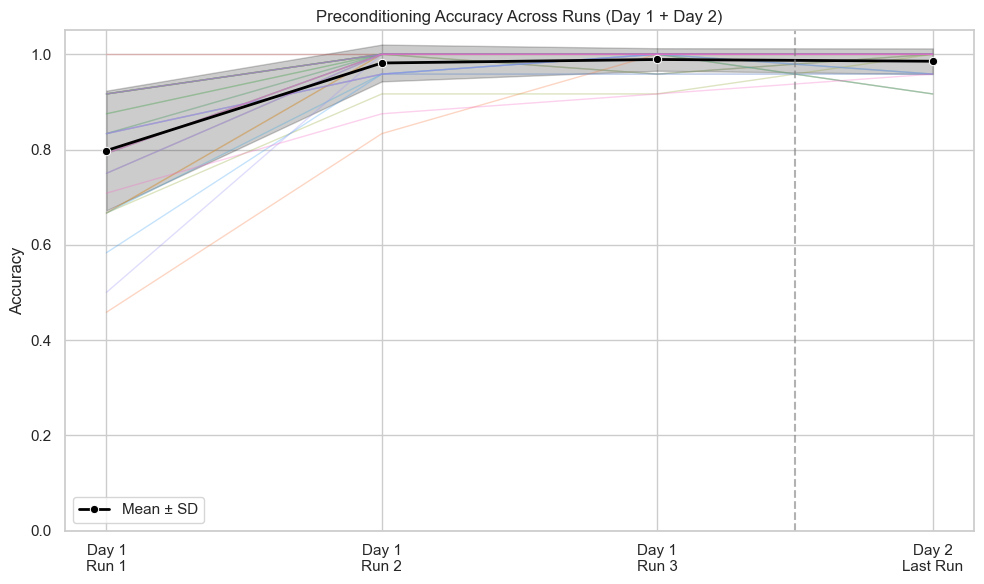

In [5]:
# -- Step 4: Plot --
sns.set(style='whitegrid')
plt.figure(figsize=(10, 6))

# Plot individual subject lines (transparent)
sns.lineplot(
    data=acc_all,
    x='run', y='acc',
    hue='SubID', estimator=None,
    units='SubID', alpha=0.3, linewidth=1, legend=False
)

# Plot group mean ± SD
sns.lineplot(
    data=acc_all,
    x='run', y='acc',
    estimator='mean', errorbar='sd',
    color='black', marker='o', linewidth=2, label='Mean ± SD'
)

# Add axis labels and styling
plt.xticks([1, 2, 3, 4], ['Day 1\nRun 1', 'Day 1\nRun 2', 'Day 1\nRun 3', 'Day 2\nLast Run'])
plt.axvline(x=3.5, color='gray', linestyle='--', alpha=0.6)
plt.xlabel('')
plt.ylabel('Accuracy')
plt.title('Preconditioning Accuracy Across Runs (Day 1 + Day 2)')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.legend()
plt.show()